# 05 - Maps

Final maps of the ZMM over the Sentinel-2 true color mosaic:

1. Vegetation detected by the Random Forest
2. Land surface temperature 2025
3. Priority AGEB

Needs the outputs of notebooks 03 and 04.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.merge import merge
from rasterio.enums import Resampling
from rasterio.features import geometry_mask

from config import s2Folder,boundaryFile,lstFile,predictionsFolder,processedFolder,resultsFolder

boundary=gpd.read_file(boundaryFile).to_crs('EPSG:4326')
ageb=gpd.read_file(processedFolder/'ageb_indicators.gpkg').to_crs('EPSG:4326')
priority=ageb[ageb['priority']==1]

# The maps are in degrees, this keeps the right proportions at the latitude of Monterrey
aspect=1/np.cos(np.radians(25.7))

def getExtent(transform,shape):
    # [left, right, bottom, top] for imshow
    H,W=shape
    return [transform.c,transform.c+W*transform.a,transform.f+H*transform.e,transform.f]

## True color background
The 2,025 tiles are joined at ~100 m resolution (enough for a figure and fast to read).

In [2]:
tilePaths=sorted(s2Folder.glob('Q??/S2_ZMM_2025_Q*.tif'))

# bands 3,2,1 = B4,B3,B2 (red, green, blue)
rgb,rgbTransform=merge(tilePaths,res=0.0009,indexes=[3,2,1],resampling=Resampling.average)
rgb=np.nan_to_num(rgb.astype('float32'))
rgbExtent=getExtent(rgbTransform,rgb.shape[1:])

# Pixels outside the ZMM become transparent
insideZmm=geometry_mask(boundary.geometry,out_shape=rgb.shape[1:],transform=rgbTransform,invert=True)

# Simple stretch with global percentiles inside the ZMM
vals=rgb[:,insideZmm]
p2,p98=np.percentile(vals[vals>0],(2,98))
rgb=np.clip((rgb-p2)/(p98-p2+1e-6),0,1)
rgba=np.dstack([np.transpose(rgb,(1,2,0)),insideZmm.astype('float32')])

def baseMap(title):
    fig,ax=plt.subplots(figsize=(10,9))
    ax.imshow(rgba,extent=rgbExtent)
    boundary.boundary.plot(ax=ax,color='black',linewidth=0.6)
    ax.set_aspect(aspect)
    ax.set_title(title,fontsize=14)
    ax.axis('off')
    return fig,ax

## 1. Vegetation

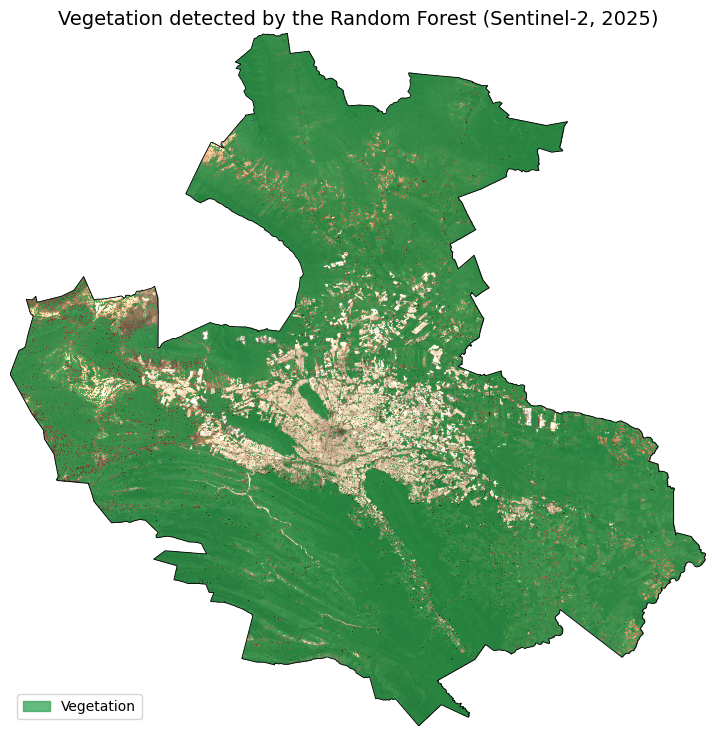

In [3]:
step=5   # 1 of every 5 pixels (~50 m), the 10 m map is too big for a figure

with rasterio.open(predictionsFolder/'GREEN_ZMM_RF.tif') as src:
    green=src.read(1,out_shape=(src.height//step,src.width//step),resampling=Resampling.nearest)
    greenTransform=src.transform*src.transform.scale(src.width/green.shape[1],src.height/green.shape[0])

greenShow=np.ma.masked_where(green!=1,green)

fig,ax=baseMap('Vegetation detected by the Random Forest (Sentinel-2, 2025)')
ax.imshow(greenShow,extent=getExtent(greenTransform,green.shape),cmap=ListedColormap(['#31a354']),
          alpha=0.75,interpolation='nearest')
ax.legend(handles=[Patch(color='#31a354',alpha=0.75,label='Vegetation')],loc='lower left')
plt.savefig(resultsFolder/'map_vegetation.png',dpi=200,bbox_inches='tight')
plt.show()

## 2. Land surface temperature

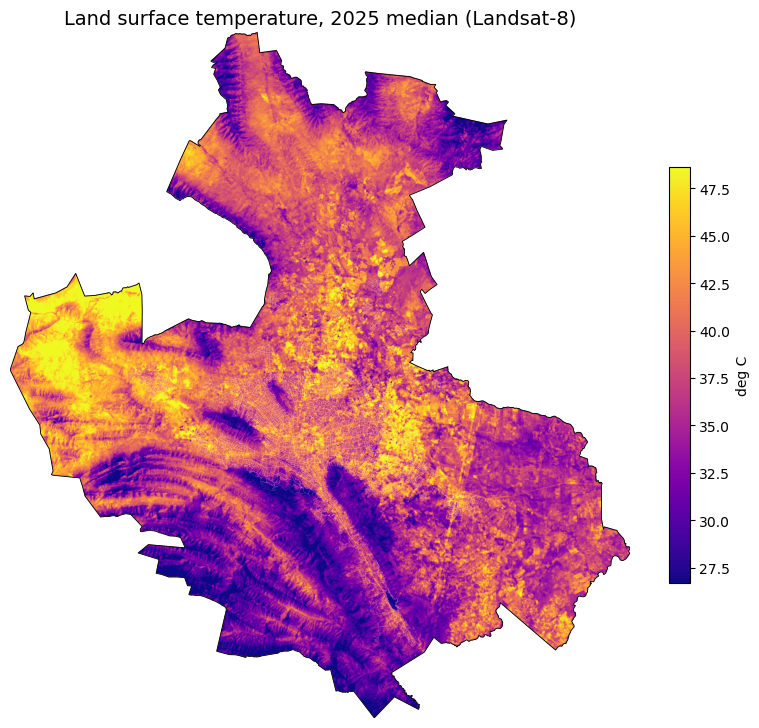

In [4]:
with rasterio.open(lstFile) as src:
    lst=src.read(1).astype('float32')
    lstTransform=src.transform

insideLst=geometry_mask(boundary.geometry,out_shape=lst.shape,transform=lstTransform,invert=True)
lst[~insideLst]=np.nan
vmin,vmax=np.nanpercentile(lst,(2,98))

fig,ax=plt.subplots(figsize=(10,9))
im=ax.imshow(lst,extent=getExtent(lstTransform,lst.shape),cmap='plasma',vmin=vmin,vmax=vmax)
ageb.boundary.plot(ax=ax,color='white',linewidth=0.1,alpha=0.5)
boundary.boundary.plot(ax=ax,color='black',linewidth=0.6)
ax.set_aspect(aspect)
ax.set_title('Land surface temperature, 2025 median (Landsat-8)',fontsize=14)
ax.axis('off')
plt.colorbar(im,ax=ax,shrink=0.6,label='deg C')
plt.savefig(resultsFolder/'map_lst.png',dpi=200,bbox_inches='tight')
plt.show()

## 3. Priority AGEB

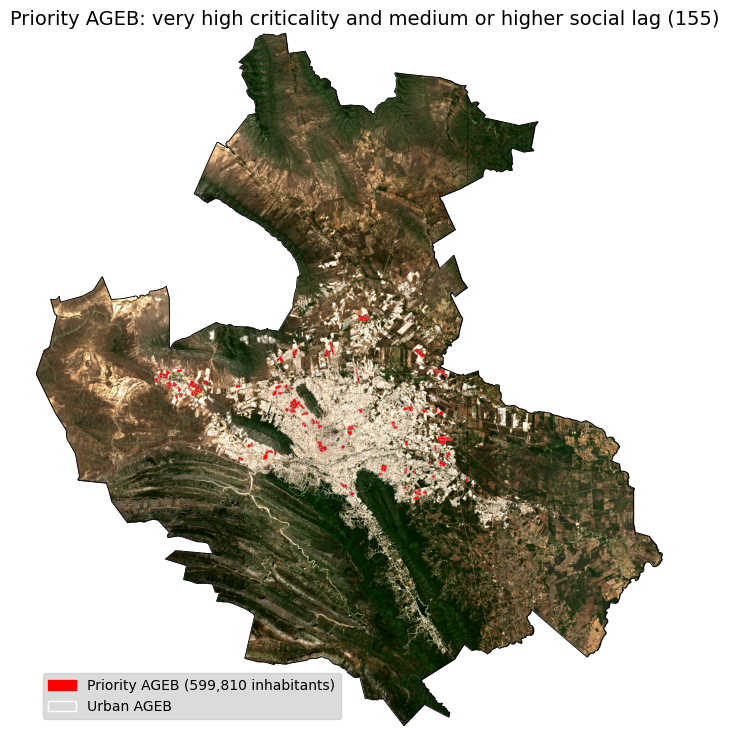

In [5]:
fig,ax=baseMap(f'Priority AGEB: very high criticality and medium or higher social lag ({len(priority)})')
ageb.boundary.plot(ax=ax,color='white',linewidth=0.15,alpha=0.6)
priority.plot(ax=ax,color='red',edgecolor='darkred',linewidth=0.3)
ax.legend(handles=[Patch(color='red',label=f'Priority AGEB ({priority["pob_tot"].sum():,} inhabitants)'),
                   Patch(facecolor='none',edgecolor='white',label='Urban AGEB')],
          loc='lower left',facecolor='lightgray')
plt.savefig(resultsFolder/'map_priority_ageb.png',dpi=200,bbox_inches='tight')
plt.show()